<a href="https://colab.research.google.com/github/TheintTheintSan/a00/blob/main/assignment6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Complete the exercises below For **Assignment #6**.

Import the following items,
- `pandas as pd`,
- `LinearRegression` from the [`sklearn.linear_model`](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.linear_model) module,
- `make_column_transformer` from [`sklearn.compose`](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.compose),
- `OneHotEncoder` from [`sklearn.preprocessing`](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.preprocessing),
- `make_pipeline` from the [`sklearn.pipeline`](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.pipeline) module, and,
- everything from the [plotnine]() package.

In [30]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from plotnine import *

## Read in our data for this exercise

Use `pd.read_csv` to read in data from the following URL: http://bit.ly/2IgDF0E. Capture the data into a dataframe called `df_voles`.

❗️Hint: just like in `R` we can read data directly from a URL.

In [2]:
from pandas.io.api import read_csv
df_voles = read_csv("http://bit.ly/2IgDF0E")


Preview the data with the `.head()` method.

The data contains the variables:

- `site` for the id of each random study site (each case or row is a survey/trapping site)
- `voles` for the vole count at each site
- `veg` for the percent cover of vegetation at each site
- `soil` identifying a site as “moist” or “dry”

In [3]:
df_voles.head()

,site,voles,veg,soil
0,1,17,4,moist
1,2,30,33,moist
2,3,54,94,moist
3,4,49,64,moist
4,5,34,32,moist


## EDA

Let's make a few figures from `df_voles` using `ggplot` from **Plotnine**.

In the cell below plot the `voles` variable (y-axis) versus the `veg` variable and color points by the `soil` variable.

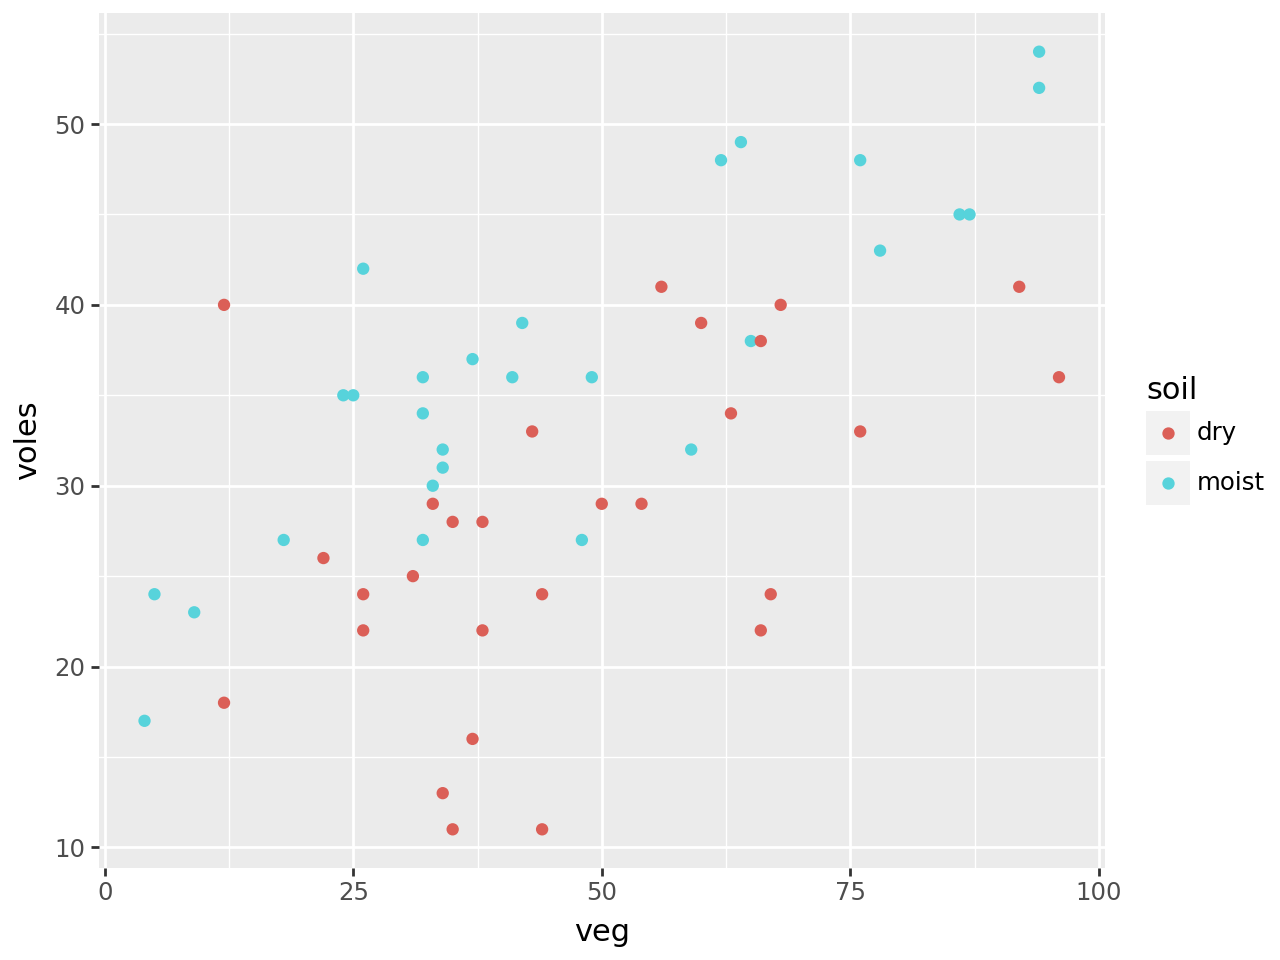

In [4]:
ggplot(df_voles, aes(x="veg", y="voles", color="soil")) + geom_point()

## Modeling

In the cell below, model `voles` with `soil` and `veg` as predictors in a parallel slopes model.

Here are the steps I would take:
1. Make a column transformer with `make_column_transformer` that transforms `soil` with `OneHotEncoder(drop="first")` and passes 'veg' through untransformed.
2. Create a pipeline with `make_pipeline` using the column transformer from above and `LinearRegression()` as my model.
3. Get the `X` (training data) and `y` predictor from `df_voles`
4. Use the `.fit()` method for the pipeline to train the model with `X` and `y`.

In [44]:
columntransformer = make_column_transformer(
    (OneHotEncoder(drop="first"), ["soil"]), remainder="passthrough",verbose_feature_names_out=False
)
# columntransformer

Use the function below to get the parameter values for your model from above.

In [54]:
def get_regression_table(pipeline):
    feature_names = list(pipeline['columntransformer'].get_feature_names_out())
    terms = ['(Intercept)'] + feature_names

    mod = pipeline['linearregression']
    # Prepend the intercept to match the length of terms
    estimates = [mod.intercept_] + list(mod.coef_)

    return pd.DataFrame({
        'term': terms,
        'estimate': estimates
    })


In [55]:
X=df_voles[["soil", "veg"]]
y=df_voles["voles"]

In [56]:
pipeline = make_pipeline(columntransformer, LinearRegression())
pipeline.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).



Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first'),
                                                  ['soil'])],
                                   verbose_feature_names_out=False)),
                ('linearregression', LinearRegression())])

In [57]:
reg_table = get_regression_table(pipeline)
reg_table

,term,estimate
0,(Intercept),15.464026
1,soil_moist,9.100298
2,veg,0.259069


❓Would protecting a site with high vegetation cover be a more effective way to preserve the vole population than a site with low vegetation cover? Why?

(**Hint:** use your chart above to answer. It's also possible to leverage your regression parameters if you chose to model `voles` with a parallel slopes model.)

**Answer:**

Based on the scatter plot and the regression meter, a site with high vegetation seems to have more vole populations. As it is 0.259 coefficient of vegetation, about 1 unit increase in vegetation adds about 0.259 vole to the predicted count. So, if we are protecting the voles instead of exterminating them, increasing 3.86 units of vegetation likely preserve the vole population by 1 volue count.

In [58]:
df_voles["predicted_voles"] = pipeline.predict(df_voles[["soil", "veg"]])

❓Dry sites typically cost a lot less to purchase and maintain for conservation organizations. Thus, if a conservation organization decides to purchase a few dry sites, roughly what percent cover of vegetation do they need to maintain on these sites (at a minimum) to support a population of about 30 voles at the site?

(**Hint:** In your chart above, draw a line at voles = 30 using `geom_hline` and make a rough estimate for this answer...)

**Answer:**

In [59]:
# Extract model parameters from reg_table using exact term names
intercept = reg_table.loc[reg_table['term'] == '(Intercept)', 'estimate'].values[0]
veg_coef = reg_table.loc[reg_table['term'] == 'veg', 'estimate'].values[0]

# At moist = 0 dry site, Voles = intercept + (0) soilm_most_coef + veg_coef * veg
# At 30 voles, Veg = (30- intercept)/veg_coef
exact_veg_at_30 = (30 - intercept) / veg_coef
print(f"Exact vegetation level needed for 30 voles at dry sites: {exact_veg_at_30:.2f}%")

Exact vegetation level needed for 30 voles at dry sites: 56.11%


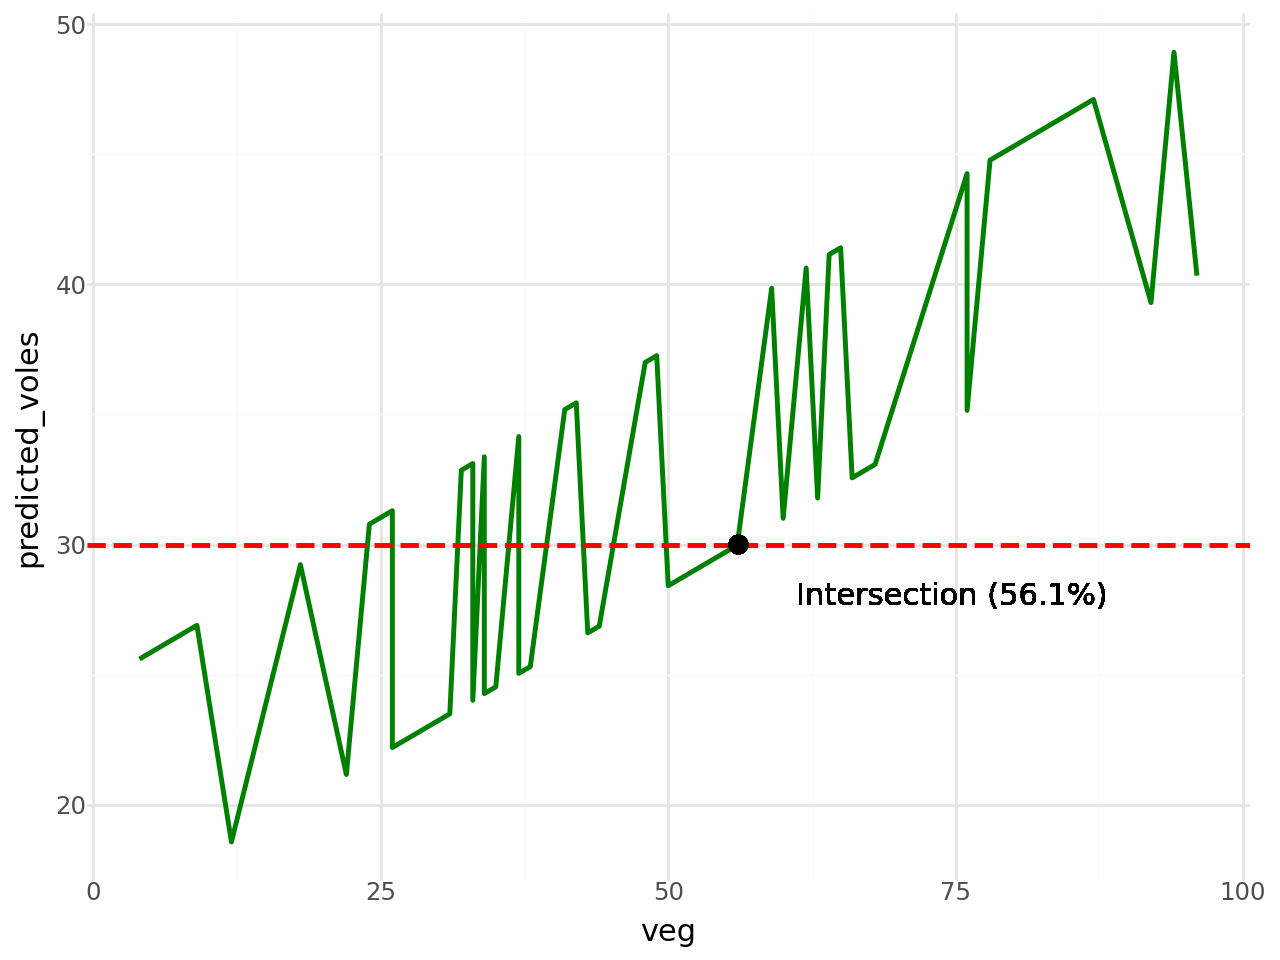

In [60]:
ggplot_obj = (
    ggplot(df_voles, aes(x="veg", y="predicted_voles"))
    + geom_line(color="green", size=1)
    + geom_hline(yintercept=30, linetype="dashed", color="red", size=1)
    + geom_point(
        aes(x=exact_veg_at_30, y=30), color="black", size=3, inherit_aes=False
    )
    + geom_text(
        aes(x=exact_veg_at_30 + 5, y=28),
        label=f"Intersection ({exact_veg_at_30:.1f}%)",
        ha="left",
        inherit_aes=False,
    )

    + theme_minimal()
)
# print(ggplot_obj)
ggplot_obj

If a conservation organization decides to purchase a few dry sites, they need to maintain on these sites (at a minimum) roughly 56 percent cover of vegetation to support a population of about 30 voles at the site.

❓The Nature Conservancy is looking at purchasing a site for this species (in the same study area) that has moist soil and 40% vegetation cover. Using the regression equation what would you predict as the possible vole population the site might be able to support?

(**Hint:** Use `.predict(pd.DataFrame({"soil": ["moist"], "veg": [40]}))` with yout pipeline.)

**Answer:**

In [65]:
predicted_voles_newsite = pipeline.predict(pd.DataFrame({'soil': ['moist'], 'veg': [40]}))[0]

print(f"Predicted vole population: {predicted_voles_newsite:.2f}")

Predicted vole population: 34.93


I would predict about 34.93 increase in the vole population at a new site that has moist soil and 40% vegetation cover.